In [2]:
import sys
import pennylane as qml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version)
print("PennyLane:", qml.__version__)
print("NumPy:", np.__version__)

print("Member 5 environment is ready!")

Python: 3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]
PennyLane: 0.45.1
NumPy: 2.4.6
Member 5 environment is ready!


In [3]:
import pennylane as qml

# Create a quantum simulator with one qubit
dev = qml.device("default.qubit", wires=1)

print("Quantum simulator created successfully!")

Quantum simulator created successfully!


In [4]:
@qml.qnode(dev)
def ideal_circuit():

    qml.RY(0.5, wires=0)

    return qml.expval(qml.PauliZ(0))


result = ideal_circuit()

print("Ideal quantum circuit output:", result)

Ideal quantum circuit output: 0.8775825618903726


In [5]:
# Create a noisy quantum simulator
dev_noise = qml.device("default.mixed", wires=1)

@qml.qnode(dev_noise)
def noisy_circuit(p):

    qml.RY(0.5, wires=0)

    # Introduce depolarizing noise
    qml.DepolarizingChannel(p, wires=0)

    return qml.expval(qml.PauliZ(0))

In [6]:
noise_levels = [0.0, 0.001, 0.005, 0.01, 0.02]

for p in noise_levels:

    result = noisy_circuit(p)

    print("Noise probability:", p,
          "| Circuit output:", result)

Noise probability: 0.0 | Circuit output: 0.8775825618903724
Noise probability: 0.001 | Circuit output: 0.876412451807852
Noise probability: 0.005 | Circuit output: 0.8717320114777701
Noise probability: 0.01 | Circuit output: 0.8658814610651677
Noise probability: 0.02 | Circuit output: 0.8541803602399626


In [7]:
import pennylane as qml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


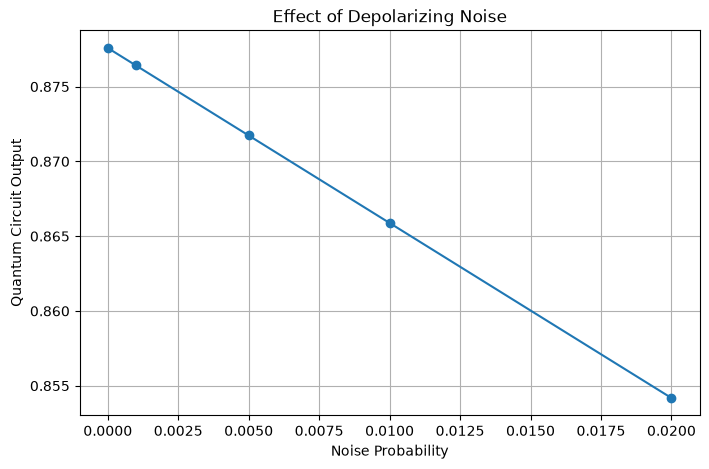

In [8]:
results = []

for p in noise_levels:
    results.append(noisy_circuit(p))

plt.figure(figsize=(8, 5))

plt.plot(noise_levels, results, marker='o')

plt.xlabel("Noise Probability")
plt.ylabel("Quantum Circuit Output")
plt.title("Effect of Depolarizing Noise")

plt.grid(True)
plt.show()

In [9]:
plt.savefig("depolarizing_noise_experiment.png", dpi=300)

<Figure size 640x480 with 0 Axes>

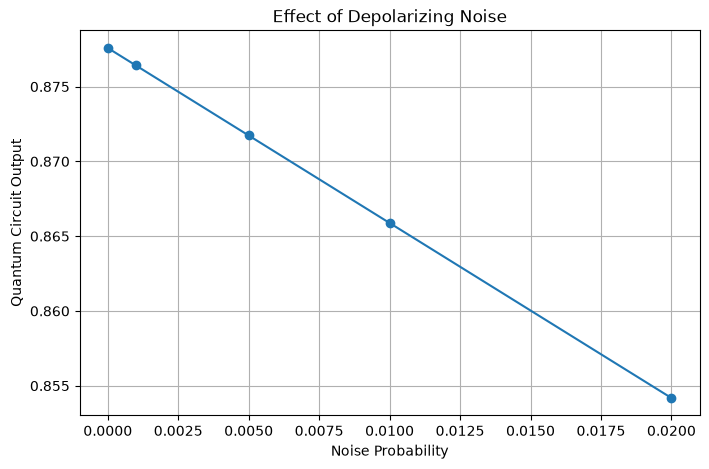

In [10]:
# Recreate the graph
plt.figure(figsize=(8, 5))

plt.plot(noise_levels, results, marker='o')

plt.xlabel("Noise Probability")
plt.ylabel("Quantum Circuit Output")
plt.title("Effect of Depolarizing Noise")

plt.grid(True)

# Save the graph BEFORE displaying it
plt.savefig("depolarizing_noise_experiment.png", dpi=300)

# Display the graph
plt.show()

In [11]:
import os

print("Saved location:", os.path.abspath("depolarizing_noise_experiment.png"))

Saved location: C:\Users\rsaho\depolarizing_noise_experiment.png


In [12]:
# Create a quantum simulator
dev_readout = qml.device("default.mixed", wires=1)

@qml.qnode(dev_readout)
def readout_circuit(p):

    # Apply quantum rotation
    qml.RY(0.5, wires=0)

    # Introduce bit-flip error
    qml.BitFlip(p, wires=0)

    # Measure the qubit
    return qml.expval(qml.PauliZ(0))

In [13]:
readout_levels = [0.0, 0.001, 0.005, 0.01, 0.02]

readout_results = []

for p in readout_levels:

    result = readout_circuit(p)

    readout_results.append(result)

    print("Readout error:", p,
          "| Circuit output:", result)

Readout error: 0.0 | Circuit output: 0.8775825618903723
Readout error: 0.001 | Circuit output: 0.8758273967665919
Readout error: 0.005 | Circuit output: 0.8688067362714688
Readout error: 0.01 | Circuit output: 0.8600309106525652
Readout error: 0.02 | Circuit output: 0.8424792594147577


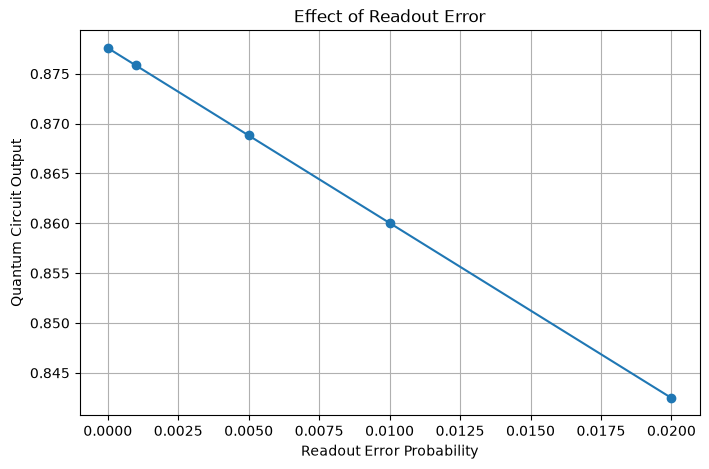

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(readout_levels, readout_results, marker='o')

plt.xlabel("Readout Error Probability")
plt.ylabel("Quantum Circuit Output")

plt.title("Effect of Readout Error")

plt.grid(True)

plt.savefig("readout_error_experiment.png", dpi=300)

plt.show()

In [15]:
import os

print(os.path.abspath("combined_noise_experiment.png"))
print(os.path.exists("combined_noise_experiment.png"))

C:\Users\rsaho\combined_noise_experiment.png
False


In [16]:
import matplotlib.pyplot as plt
import os

plt.figure(figsize=(8, 5))

plt.plot(noise_levels, combined_results, marker='o')

plt.xlabel("Noise Probability")
plt.ylabel("Quantum Circuit Output")
plt.title("Effect of Combined Quantum Noise")

plt.grid(True)

# Save the graph
plt.savefig("combined_noise_experiment.png", dpi=300, bbox_inches="tight")

print("Graph saved:", os.path.exists("combined_noise_experiment.png"))
print("Location:", os.path.abspath("combined_noise_experiment.png"))

plt.show()

NameError: name 'combined_results' is not defined

<Figure size 800x500 with 0 Axes>

In [17]:
noise_levels = [0.0, 0.001, 0.005, 0.01, 0.02]

combined_results = []

for p in noise_levels:
    result = combined_noise_circuit(p)
    combined_results.append(result)

    print("Noise probability:", p,
          "| Combined output:", result)

NameError: name 'combined_noise_circuit' is not defined

In [18]:
dev_combined = qml.device("default.mixed", wires=1)

@qml.qnode(dev_combined)
def combined_noise_circuit(p):
    qml.RY(0.5, wires=0)
    qml.DepolarizingChannel(p, wires=0)
    qml.BitFlip(p, wires=0)
    return qml.expval(qml.PauliZ(0))

In [19]:
noise_levels = [0.0, 0.001, 0.005, 0.01, 0.02]

combined_results = []

for p in noise_levels:
    result = combined_noise_circuit(p)
    combined_results.append(result)

    print("Noise probability:", p,
          "| Combined output:", result)

Noise probability: 0.0 | Combined output: 0.8775825618903723
Noise probability: 0.001 | Combined output: 0.8746596269042364
Noise probability: 0.005 | Combined output: 0.8630146913629924
Noise probability: 0.01 | Combined output: 0.8485638318438645
Noise probability: 0.02 | Combined output: 0.8200131458303641


Graph saved: True
File location: C:\Users\rsaho\combined_noise_experiment.png


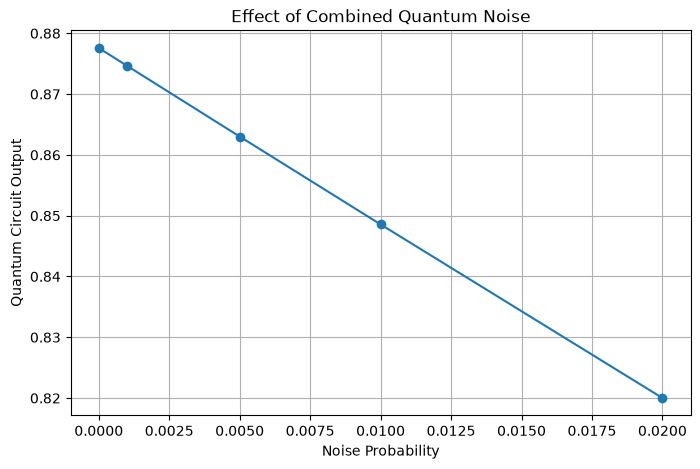

In [20]:
import matplotlib.pyplot as plt
import os

plt.figure(figsize=(8, 5))
plt.plot(noise_levels, combined_results, marker='o')

plt.xlabel("Noise Probability")
plt.ylabel("Quantum Circuit Output")
plt.title("Effect of Combined Quantum Noise")
plt.grid(True)

plt.savefig("combined_noise_experiment.png",
            dpi=300, bbox_inches="tight")

print("Graph saved:", os.path.exists("combined_noise_experiment.png"))
print("File location:", os.path.abspath("combined_noise_experiment.png"))

plt.show()

In [21]:
import os

files = [
    "depolarizing_noise_experiment.png",
    "readout_error_experiment.png",
    "combined_noise_experiment.png"
]

for file in files:
    if os.path.exists(file):
        print("SUCCESS:", file, "is saved.")
        print("File size:", os.path.getsize(file), "bytes")
    else:
        print("NOT FOUND:", file)

SUCCESS: depolarizing_noise_experiment.png is saved.
File size: 119238 bytes
SUCCESS: readout_error_experiment.png is saved.
File size: 127350 bytes
SUCCESS: combined_noise_experiment.png is saved.
File size: 120702 bytes


In [23]:
dev_stability = qml.device("default.mixed", wires=1)

@qml.qnode(dev_stability, shots=1000)
def stability_circuit(p):
    qml.RY(0.5, wires=0)

    qml.DepolarizingChannel(p, wires=0)
    qml.BitFlip(p, wires=0)

    return qml.expval(qml.PauliZ(0))

print("Stability experiment circuit created successfully!")

Stability experiment circuit created successfully!


In [24]:
noise_levels = [0.0, 0.001, 0.005, 0.01, 0.02]

number_of_runs = 30

stability_results = []

for p in noise_levels:

    outputs = []

    for i in range(number_of_runs):
        result = stability_circuit(p)
        outputs.append(result)

    mean_output = np.mean(outputs)
    std_output = np.std(outputs)

    stability_results.append({
        "Noise Probability": p,
        "Mean Output": mean_output,
        "Standard Deviation": std_output
    })

    print(
        "Noise:", p,
        "| Mean:", mean_output,
        "| Standard Deviation:", std_output
    )

Noise: 0.0 | Mean: 0.8754666666666664 | Standard Deviation: 0.014741626625157617
Noise: 0.001 | Mean: 0.8779333333333331 | Standard Deviation: 0.016982212916918576
Noise: 0.005 | Mean: 0.8625333333333334 | Standard Deviation: 0.014179170952100452
Noise: 0.01 | Mean: 0.8442666666666665 | Standard Deviation: 0.019271625659387316
Noise: 0.02 | Mean: 0.8206 | Standard Deviation: 0.01788966181905066


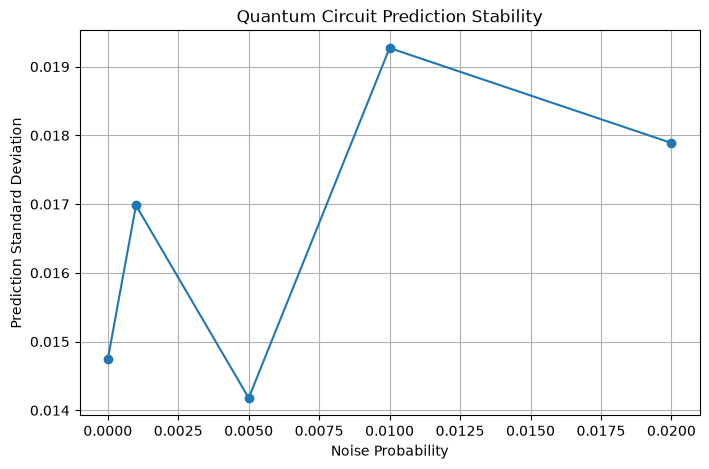

In [25]:
noise_values = [x["Noise Probability"] for x in stability_results]
std_values = [x["Standard Deviation"] for x in stability_results]

plt.figure(figsize=(8, 5))

plt.plot(noise_values, std_values, marker='o')

plt.xlabel("Noise Probability")
plt.ylabel("Prediction Standard Deviation")
plt.title("Quantum Circuit Prediction Stability")

plt.grid(True)

plt.savefig(
    "noise_prediction_std.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
stability_df = pd.DataFrame(stability_results)

stability_df.to_csv(
    "noise_stability.csv",
    index=False
)

print(stability_df)
print("\nCSV saved successfully!")

   Noise Probability  Mean Output  Standard Deviation
0              0.000     0.875467            0.014742
1              0.001     0.877933            0.016982
2              0.005     0.862533            0.014179
3              0.010     0.844267            0.019272
4              0.020     0.820600            0.017890

CSV saved successfully!


In [27]:
import os

for file in ["noise_prediction_std.png", "noise_stability.csv"]:
    print(file, ":", os.path.exists(file))

noise_prediction_std.png : True
noise_stability.csv : True


In [1]:
import os

print("Current directory:")
print(os.getcwd())

print("\nChecking important project files:")

files = [
    "config.yaml",
    "src/quantum/quantum_model.py",
    "src/quantum/train.py",
    "src/data_io.py",
    "data/processed/X_test.npy",
    "data/processed/y_test.npy"
]

for file in files:
    print(file, ":", os.path.exists(file))

print("\nAvailable model checkpoints:")

if os.path.exists("models"):
    print(os.listdir("models"))
else:
    print("Models folder not found")

Current directory:
C:\Users\rsaho

Checking important project files:
config.yaml : False
src/quantum/quantum_model.py : False
src/quantum/train.py : False
src/data_io.py : False
data/processed/X_test.npy : False
data/processed/y_test.npy : False

Available model checkpoints:
Models folder not found


In [2]:
import os

print("Folders in your user directory:\n")

for item in os.listdir(r"C:\Users\rsaho"):
    if os.path.isdir(os.path.join(r"C:\Users\rsaho", item)):
        print(item)

Folders in your user directory:

.anaconda
.android
.arduinoIDE
.conda
.continuum
.idlerc
.ipynb_checkpoints
.ipython
.jupyter
.matplotlib
.streamlit
.vscode
anaconda_projects
AppData
Application Data
Cisco Packet Tracer 6.2sv
Contacts
Cookies
CrossDevice
Documents
Downloads
Favorites
Links
Local Settings
Music
My Documents
NetHood
OneDrive
Oracle
Pictures
PrintHood
Recent
Saved Games
Searches
SendTo
Start Menu
streamlit_lab
Templates
Videos


In [7]:
import os

path = r"C:\Users\rsaho\Downloads"

for item in os.listdir(path):
    print(item)

0 Neural-Network(Basics).pdf
0749de342a6b5a950749de342a6b5a95WhatsAppImage2024-03-23at11.41.31_4fb80c7d.jpg
1. Digital Forensic Introduction.pdf
12023002029119.pdf
1698328213208.jpg
19363 (1).pdf
19363.pdf
2 Digital Forensic Investigations and Evidence.pdf
2366.pdf
3. Sorting.docx
3. Sorting.pdf
322e099a0e8dbcf5322e099a0e8dbcf50749de342a6b5a950749de342a6b5a95WhatsAppImage2024-03-23at11.41.31_4fb80c7d.jpg
4 Digital Forensic Investigation Phases (1)_260126_184359.pdf
43rc3v3d6 - HTML - OneCompiler.html
43rc3v3d6 - HTML - OneCompiler_files
A HYBRID QUANTUM KEY DISTRIBUTION ARCHITECTURE WITH ML[1].docx
A HYBRID QUANTUM KEY DISTRIBUTION ARCHITECTURE WITH ML[1][1].docx
ADMIT .4.pdf
admit tcs.pdf
Anaconda3-2025.12-2-Windows-x86_64.exe
android-studio-2024.1.1.11-windows.exe
ANI SIG.jpeg
ANI SIG.jpg
anisa railway payment.pdf
anisa sahoo image.jpg
anisa sahoo signature.jpeg
Annapurna_Application_318104502346.png
Annapurna_Yojana_Family_Level_Data_Collection_Form.pdf
ApplicationForm (1).pdf
Appli

In [9]:
import os

search_path = r"C:\Users\rsaho\Downloads"

for root, dirs, files in os.walk(search_path):
    if "config.yaml" in files:
        print("PROJECT FOUND:")
        print(root)

In [10]:
import os

paths = [
    r"C:\Users\rsaho\Documents\GitHub",
    r"C:\Users\rsaho\Downloads\GitHub",
    r"C:\Users\rsaho\OneDrive\Documents\GitHub",
    r"C:\Users\rsaho\source\repos"
]

for path in paths:
    print("\nChecking:", path)
    if os.path.exists(path):
        print("FOUND:", os.listdir(path))
    else:
        print("Not found")


Checking: C:\Users\rsaho\Documents\GitHub
Not found

Checking: C:\Users\rsaho\Downloads\GitHub
Not found

Checking: C:\Users\rsaho\OneDrive\Documents\GitHub
Not found

Checking: C:\Users\rsaho\source\repos
Not found


In [11]:
import os

project_path = r"C:\Users\rsaho\Downloads\Quantum-XAI-main"

os.chdir(project_path)

print("Current directory:", os.getcwd())

print("\nChecking project files:")

files = [
    "config.yaml",
    "src/quantum/quantum_model.py",
    "src/quantum/train.py",
    "src/data_io.py",
    "data/processed/X_test.npy",
    "data/processed/y_test.npy"
]

for file in files:
    print(file, ":", os.path.exists(file))

Current directory: C:\Users\rsaho\Downloads\Quantum-XAI-main

Checking project files:
config.yaml : False
src/quantum/quantum_model.py : False
src/quantum/train.py : False
src/data_io.py : False
data/processed/X_test.npy : False
data/processed/y_test.npy : False


In [12]:
import os

path = r"C:\Users\rsaho\Downloads\Quantum-XAI-main"

print("Items inside Quantum-XAI-main:\n")

for item in os.listdir(path):
    print(item)

Items inside Quantum-XAI-main:

Quantum-XAI-main


In [13]:
import os

project_path = r"C:\Users\rsaho\Downloads\Quantum-XAI-main\Quantum-XAI-main"

os.chdir(project_path)

print("Current directory:", os.getcwd())
print("\nProject files:", os.listdir())

Current directory: C:\Users\rsaho\Downloads\Quantum-XAI-main\Quantum-XAI-main

Project files: ['.gitignore', 'config.yaml', 'data', 'LICENSE', 'models', 'README.md', 'requirements.txt', 'results', 'scripts', 'src', 'tests']


In [14]:
import os

print("Checking important files:\n")

files = [
    "config.yaml",
    "src/quantum/quantum_model.py",
    "src/quantum/train.py",
    "src/data_io.py",
    "data/processed/X_test.npy",
    "data/processed/y_test.npy"
]

for file in files:
    print(file, ":", os.path.exists(file))

print("\nAvailable model checkpoints:")

model_path = "models"

if os.path.exists(model_path):
    print(os.listdir(model_path))

Checking important files:

config.yaml : True
src/quantum/quantum_model.py : True
src/quantum/train.py : True
src/data_io.py : True
data/processed/X_test.npy : True
data/processed/y_test.npy : True

Available model checkpoints:
['.gitkeep']


In [15]:
import numpy as np
import json
import os

# Load dataset
X_train = np.load("data/processed/X_train.npy")
X_val = np.load("data/processed/X_val.npy")
X_test = np.load("data/processed/X_test.npy")

y_train = np.load("data/processed/y_train.npy")
y_val = np.load("data/processed/y_val.npy")
y_test = np.load("data/processed/y_test.npy")

print("DATASET INFORMATION")
print("-------------------")

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)
print("y_test shape:", y_test.shape)

print("\nFeature names:")

with open("data/processed/feature_names.json") as f:
    print(json.load(f))

print("\nMissing values:", np.isnan(X_train).sum())
print("Dataset loaded successfully!")

DATASET INFORMATION
-------------------
X_train shape: (498, 8)
X_val shape: (107, 8)
X_test shape: (107, 8)
y_train shape: (498,)
y_val shape: (107,)
y_test shape: (107,)

Feature names:
['ETV4', 'DUSP6', 'SPRY2', 'TYR', 'LYZ', 'CAPN3', 'S100B', 'ETV5']

Missing values: 0
Dataset loaded successfully!


In [16]:
import torch
import pennylane as qml
import numpy as np

print("PyTorch version:", torch.__version__)
print("PennyLane version:", qml.__version__)
print("NumPy version:", np.__version__)

print("\nChecking configuration:")

with open("config.yaml") as f:
    print(f.read())

ModuleNotFoundError: No module named 'torch'

In [17]:
import sys

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

Python executable:
C:\Users\rsaho\.conda\envs\member5\python.exe

Python version:
3.11.18 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 18:13:29) [MSC v.1942 64 bit (AMD64)]


In [18]:
with open("requirements.txt", "r") as f:
    print(f.read())

numpy
pandas
scipy
scikit-learn
xgboost
torch
pennylane
shap
lime
matplotlib
seaborn
streamlit
pyyaml
openpyxl
joblib
statsmodels
jupyter
pytest


In [19]:
%pip install torch pennylane pyyaml pandas scikit-learn

   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.5/126.7 MB 2.4 MB/s eta 0:00:53
   ---------------------------------------- 1.0/126.7 MB 1.9 MB/s eta 0:01:05
   ---------------------------------------- 1.3/126.7 MB 1.7 MB/s eta 0:01:15
    --------------------------------------- 1.8/126.7 MB 1.8 MB/s eta 0:01:11
    --------------------------------------- 2.1/126.7 MB 1.8 MB/s eta 0:01:10
    --------------------------------------- 2.6/126.7 MB 1.8 MB/s eta 0:01:09
    --------------------------------------- 2.9/126.7 MB 1.8 MB/s eta 0:01:09
    --------------------------------------- 3.1/126.7 MB 1.8 MB/s eta 0:01:11
   - -------------------------------------- 3.4/126.7 MB 1.7 MB/s eta 0:01:12
   - -------------------------------------- 3.7/126.7 MB 1.7 MB/s eta 0:01:14
   - -------------------------------------- 4.2/126.7 MB 1.7 MB/s eta 0:01:14


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
import torch
import pennylane as qml
import numpy as np
import yaml

print("PyTorch:", torch.__version__)
print("PennyLane:", qml.__version__)
print("NumPy:", np.__version__)
print("CUDA available:", torch.cuda.is_available())

print("All packages imported successfully!")

PyTorch: 2.15.0+cpu
PennyLane: 0.45.1
NumPy: 2.4.6
CUDA available: False
All packages imported successfully!


In [2]:
!python -m src.quantum.train --seed 0 --p_train 0.0 --name qnn_ideal

C:\ProgramData\anaconda3\python.exe: Error while finding module specification for 'src.quantum.train' (ModuleNotFoundError: No module named 'src')


In [3]:
import sys
import os
import subprocess

project_path = r"C:\Users\rsaho\Downloads\Quantum-XAI-main\Quantum-XAI-main"

os.chdir(project_path)

print("Using Python:", sys.executable)
print("Project directory:", os.getcwd())

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "src.quantum.train",
        "--seed", "0",
        "--p_train", "0.0",
        "--name", "qnn_ideal"
    ],
    cwd=project_path
)

print("\nTraining process finished with exit code:", result.returncode)

Using Python: C:\Users\rsaho\.conda\envs\member5\python.exe
Project directory: C:\Users\rsaho\Downloads\Quantum-XAI-main\Quantum-XAI-main

Training process finished with exit code: 0


In [4]:
import os

print("MODEL CHECKPOINTS:")
print(os.listdir("models"))

print("\nRESULT TABLES:")
print(os.listdir("results/tables"))

print("\nPREDICTIONS:")
print(os.listdir("results/predictions"))

MODEL CHECKPOINTS:
['.gitkeep', 'qnn_ideal_seed0.pt']

RESULT TABLES:
['loss_qnn_ideal_seed0.csv', 'quantum_metrics.csv']

PREDICTIONS:
['.gitkeep', 'qnn_ideal_seed0_p0.0.npy']


In [5]:
import sys
import os
import subprocess

project_path = r"C:\Users\rsaho\Downloads\Quantum-XAI-main\Quantum-XAI-main"

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "src.quantum.train",
        "--seed", "0",
        "--p_train", "0.01",
        "--name", "qnn_noise_aware"
    ],
    cwd=project_path
)

print("Training exit code:", result.returncode)

Training exit code: 0


In [6]:
import os

project_path = r"C:\Users\rsaho\Downloads\Quantum-XAI-main\Quantum-XAI-main"

folders = {
    "MODEL CHECKPOINTS": "models",
    "RESULT TABLES": "results/tables",
    "PREDICTIONS": "results/predictions"
}

for title, folder in folders.items():
    print("\n" + title + ":")
    path = os.path.join(project_path, folder)

    if os.path.exists(path):
        print(os.listdir(path))
    else:
        print("Folder not found")


MODEL CHECKPOINTS:
['.gitkeep', 'qnn_ideal_seed0.pt', 'qnn_noise_aware_seed0.pt']

RESULT TABLES:
['loss_qnn_ideal_seed0.csv', 'loss_qnn_noise_aware_seed0.csv', 'quantum_metrics.csv']

PREDICTIONS:
['.gitkeep', 'qnn_ideal_seed0_p0.0.npy', 'qnn_noise_aware_seed0_p0.0.npy']


In [7]:
import sys
import subprocess

project_path = r"C:\Users\rsaho\Downloads\Quantum-XAI-main\Quantum-XAI-main"

result = subprocess.run(
    [
        sys.executable,
        "-u",
        "-m",
        "src.quantum.train",
        "--seed", "1",
        "--p_train", "0.0",
        "--name", "qnn_ideal"
    ],
    cwd=project_path
)

print("Training exit code:", result.returncode)

Training exit code: 0


In [8]:
import sys
import subprocess

project_path = r"C:\Users\rsaho\Downloads\Quantum-XAI-main\Quantum-XAI-main"

result = subprocess.run(
    [
        sys.executable,
        "-u",
        "-m",
        "src.quantum.train",
        "--seed", "1",
        "--p_train", "0.01",
        "--name", "qnn_noise_aware"
    ],
    cwd=project_path
)

print("Training exit code:", result.returncode)

Training exit code: 0


In [9]:
import sys
import subprocess

project_path = r"C:\Users\rsaho\Downloads\Quantum-XAI-main\Quantum-XAI-main"

result = subprocess.run(
    [
        sys.executable,
        "-u",
        "-m",
        "src.quantum.train",
        "--seed", "2",
        "--p_train", "0.0",
        "--name", "qnn_ideal"
    ],
    cwd=project_path
)

print("Training exit code:", result.returncode)

Training exit code: 0


In [10]:
import sys
import subprocess

project_path = r"C:\Users\rsaho\Downloads\Quantum-XAI-main\Quantum-XAI-main"

result = subprocess.run(
    [
        sys.executable,
        "-u",
        "-m",
        "src.quantum.train",
        "--seed", "2",
        "--p_train", "0.01",
        "--name", "qnn_noise_aware"
    ],
    cwd=project_path
)

print("Training exit code:", result.returncode)

Training exit code: 0


In [11]:
import os

project_path = r"C:\Users\rsaho\Downloads\Quantum-XAI-main\Quantum-XAI-main"
model_path = os.path.join(project_path, "models")

expected_models = [
    "qnn_ideal_seed0.pt",
    "qnn_ideal_seed1.pt",
    "qnn_ideal_seed2.pt",
    "qnn_noise_aware_seed0.pt",
    "qnn_noise_aware_seed1.pt",
    "qnn_noise_aware_seed2.pt"
]

for model in expected_models:
    path = os.path.join(model_path, model)

    if os.path.exists(path):
        print("✅ Found:", model)
    else:
        print("❌ Missing:", model)

✅ Found: qnn_ideal_seed0.pt
✅ Found: qnn_ideal_seed1.pt
✅ Found: qnn_ideal_seed2.pt
✅ Found: qnn_noise_aware_seed0.pt
✅ Found: qnn_noise_aware_seed1.pt
✅ Found: qnn_noise_aware_seed2.pt


In [12]:
import inspect
from src.quantum.quantum_model import load_model, HybridQNN, make_qlayer

print("LOAD MODEL:")
print(inspect.signature(load_model))

print("\nQUANTUM LAYER:")
print(inspect.signature(make_qlayer))

print("\nHYBRID MODEL:")
print(inspect.signature(HybridQNN))

print("\nPREDICTION FUNCTION:")
print(inspect.getsource(HybridQNN))

LOAD MODEL:
(path, p_dep=0.0, p_ro=0.0, shots=None)

QUANTUM LAYER:
(n_qubits=4, n_layers=3, p_dep=0.0, p_ro=0.0, shots=None)

HYBRID MODEL:
(n_qubits=4, n_layers=3, p_dep=0.0, p_ro=0.0, shots=None)

PREDICTION FUNCTION:
class HybridQNN(nn.Module):
    def __init__(self, n_qubits=4, n_layers=3, p_dep=0.0, p_ro=0.0, shots=None):
        super().__init__()
        self.n_qubits = n_qubits
        self.q = make_qlayer(n_qubits, n_layers, p_dep, p_ro, shots)
        self.head = nn.Linear(n_qubits, 1)
        self.double()

    def forward(self, x):
        return self.head(self.q(x.double())).squeeze(-1)



In [13]:
import os
import numpy as np

project_path = r"C:\Users\rsaho\Downloads\Quantum-XAI-main\Quantum-XAI-main"

os.chdir(project_path)

X_test = np.load("data/processed/X_test.npy")
y_test = np.load("data/processed/y_test.npy")

print("Test dataset loaded successfully!")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nFirst 5 test samples:")
print(X_test[:5])

print("\nFirst 5 actual values:")
print(y_test[:5])

Test dataset loaded successfully!
X_test shape: (107, 8)
y_test shape: (107,)

First 5 test samples:
[[0.52169759 0.36917487 0.31899136 0.         0.00226921 0.0888345
  0.         0.5421054 ]
 [0.6085112  0.41888113 0.72156589 0.         0.01400511 0.03305501
  0.         0.46496155]
 [0.74783839 0.99357104 0.77884759 0.05839651 0.04646289 0.1384223
  0.03208543 0.64036456]
 [0.4383909  0.6698908  0.43909985 0.00311227 0.06542946 0.0444698
  0.01144101 0.3369187 ]
 [0.53923268 0.66974095 0.57127513 0.02995871 0.61972431 0.36853316
  0.10305318 0.6403183 ]]

First 5 actual values:
[-0.126099  0.583593 -0.423498 -1.015797 -1.994334]


In [14]:
import torch
import numpy as np

from src.quantum.quantum_model import load_model

model_path = "models/qnn_ideal_seed0.pt"

model = load_model(model_path)

model.eval()

X_test_tensor = torch.tensor(
    X_test[:, :4],
    dtype=torch.float64
)

with torch.no_grad():
    predictions = model(X_test_tensor).cpu().numpy()

print("Prediction test completed!")

print("Actual values:", y_test[:10])
print("Predicted values:", predictions[:10])

print("\nPrediction shape:", predictions.shape)
print("Mean prediction:", np.mean(predictions))
print("Prediction standard deviation:", np.std(predictions))
print("Any NaN values:", np.isnan(predictions).any())

AttributeError: 'tuple' object has no attribute 'eval'

In [15]:
import inspect
from src.quantum.quantum_model import load_model

print(inspect.getsource(load_model))

def load_model(path, p_dep=0.0, p_ro=0.0, shots=None):
    ck = torch.load(path, weights_only=False)
    m = HybridQNN(ck['n_qubits'], ck['n_layers'], p_dep, p_ro, shots)
    m.load_state_dict(ck['state'])
    m.eval()
    return m, ck['mu'], ck['sd']



In [16]:
import torch
import numpy as np

from src.quantum.quantum_model import load_model

# Load model and normalization parameters
model, mu, sd = load_model("models/qnn_ideal_seed0.pt")

model.eval()

# Select first four features
X_test_4 = X_test[:, :4]

# Apply training normalization
X_test_scaled = (X_test_4 - mu) / sd

# Convert to PyTorch tensor
X_test_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float64
)

# Generate predictions
with torch.no_grad():
    predictions = model(X_test_tensor).cpu().numpy()

print("Prediction test completed!")

print("Actual values:", y_test[:10])
print("Predicted values:", predictions[:10])

print("\nPrediction shape:", predictions.shape)
print("Mean prediction:", np.mean(predictions))
print("Prediction standard deviation:", np.std(predictions))
print("Any NaN values:", np.isnan(predictions).any())

Prediction test completed!
Actual values: [-0.126099  0.583593 -0.423498 -1.015797 -1.994334  0.915046  1.187328
  2.089611  1.368211  5.099511]
Predicted values: [0.59102122 0.56505799 0.32125473 0.55855305 0.53578717 0.54316682
 0.52637948 0.62565559 0.17225888 0.65092765]

Prediction shape: (107,)
Mean prediction: 0.5600914844231059
Prediction standard deviation: 0.09752762390586418
Any NaN values: False


In [17]:
import torch
import numpy as np

from src.quantum.quantum_model import load_model

noise_levels = [0.0, 0.001, 0.005, 0.01, 0.02]

results = []

X_test_4 = X_test[:, :4]

for p in noise_levels:

    model, mu, sd = load_model(
        "models/qnn_ideal_seed0.pt",
        p_dep=p,
        p_ro=0.0
    )

    model.eval()

    X_scaled = (X_test_4 - mu) / sd

    X_tensor = torch.tensor(
        X_scaled,
        dtype=torch.float64
    )

    with torch.no_grad():
        pred = model(X_tensor).cpu().numpy()

    results.append({
        "Noise Level": p,
        "Mean Prediction": np.mean(pred),
        "Prediction Std": np.std(pred)
    })

import pandas as pd

noise_df = pd.DataFrame(results)

print(noise_df)

   Noise Level  Mean Prediction  Prediction Std
0        0.000         0.560091        0.097528
1        0.001         0.552758        0.096287
2        0.005         0.524167        0.091474
3        0.010         0.490047        0.085784
4        0.020         0.426909        0.075411


In [18]:
import torch
import numpy as np
import pandas as pd

from src.quantum.quantum_model import load_model

noise_levels = [0.0, 0.001, 0.005, 0.01, 0.02]

results_readout = []

X_test_4 = X_test[:, :4]

for p in noise_levels:

    model, mu, sd = load_model(
        "models/qnn_ideal_seed0.pt",
        p_dep=0.0,
        p_ro=p
    )

    model.eval()

    X_scaled = (X_test_4 - mu) / sd

    X_tensor = torch.tensor(
        X_scaled,
        dtype=torch.float64
    )

    with torch.no_grad():
        pred = model(X_tensor).cpu().numpy()

    results_readout.append({
        "Noise Level": p,
        "Mean Prediction": np.mean(pred),
        "Prediction Std": np.std(pred)
    })

readout_df = pd.DataFrame(results_readout)

print(readout_df)

   Noise Level  Mean Prediction  Prediction Std
0        0.000         0.560091        0.097528
1        0.001         0.558818        0.097333
2        0.005         0.553724        0.096552
3        0.010         0.547357        0.095577
4        0.020         0.534623        0.093627


In [19]:
import torch
import numpy as np
import pandas as pd

from src.quantum.quantum_model import load_model

noise_levels = [0.0, 0.001, 0.005, 0.01, 0.02]

results_combined = []

X_test_4 = X_test[:, :4]

for p in noise_levels:

    model, mu, sd = load_model(
        "models/qnn_ideal_seed0.pt",
        p_dep=p,
        p_ro=p
    )

    model.eval()

    X_scaled = (X_test_4 - mu) / sd

    X_tensor = torch.tensor(
        X_scaled,
        dtype=torch.float64
    )

    with torch.no_grad():
        pred = model(X_tensor).cpu().numpy()

    results_combined.append({
        "Noise Level": p,
        "Mean Prediction": np.mean(pred),
        "Prediction Std": np.std(pred)
    })

combined_df = pd.DataFrame(results_combined)

print(combined_df)

   Noise Level  Mean Prediction  Prediction Std
0        0.000         0.560091        0.097528
1        0.001         0.551500        0.096094
2        0.005         0.518159        0.090559
3        0.010         0.478714        0.084068
4        0.020         0.406768        0.072395


In [21]:
import pandas as pd
import os

comparison_df = pd.DataFrame({
    "Noise Level": noise_levels,
    "Depolarizing": noise_df["Mean Prediction"].values,
    "Readout": readout_df["Mean Prediction"].values,
    "Combined": combined_df["Mean Prediction"].values
})

print("NOISE EXPERIMENT COMPARISON")
print(comparison_df)

os.makedirs("results/tables", exist_ok=True)

comparison_df.to_csv(
    "results/tables/noise_comparison_seed0.csv",
    index=False
)

print("\nComparison table saved successfully!")

NOISE EXPERIMENT COMPARISON
   Noise Level  Depolarizing   Readout  Combined
0        0.000      0.560091  0.560091  0.560091
1        0.001      0.552758  0.558818  0.551500
2        0.005      0.524167  0.553724  0.518159
3        0.010      0.490047  0.547357  0.478714
4        0.020      0.426909  0.534623  0.406768

Comparison table saved successfully!


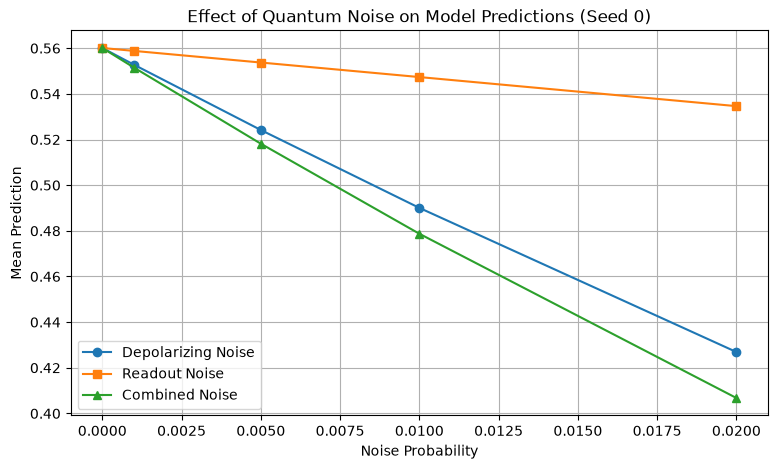

Graph saved successfully!


In [22]:
import matplotlib.pyplot as plt
import os

plt.figure(figsize=(9, 5))

plt.plot(
    comparison_df["Noise Level"],
    comparison_df["Depolarizing"],
    marker="o",
    label="Depolarizing Noise"
)

plt.plot(
    comparison_df["Noise Level"],
    comparison_df["Readout"],
    marker="s",
    label="Readout Noise"
)

plt.plot(
    comparison_df["Noise Level"],
    comparison_df["Combined"],
    marker="^",
    label="Combined Noise"
)

plt.xlabel("Noise Probability")
plt.ylabel("Mean Prediction")
plt.title("Effect of Quantum Noise on Model Predictions (Seed 0)")
plt.legend()
plt.grid(True)

os.makedirs("results/figures", exist_ok=True)

plt.savefig(
    "results/figures/noise_comparison_seed0.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved successfully!")

In [23]:
import os
import numpy as np
import pandas as pd
import torch

from src.quantum.quantum_model import load_model

noise_levels = [0.0, 0.001, 0.005, 0.01, 0.02]

noise_types = {
    "Depolarizing": (1, 0),
    "Readout": (0, 1),
    "Combined": (1, 1)
}

results = []

X_test = np.load("data/processed/X_test.npy")

for seed in [0, 1, 2]:

    for noise_name, (dep, ro) in noise_types.items():

        for p in noise_levels:

            model, mu, sd = load_model(
                f"models/qnn_ideal_seed{seed}.pt",
                p_dep=dep * p,
                p_ro=ro * p
            )

            X_scaled = (X_test[:, :4] - mu) / sd
            X_tensor = torch.tensor(
                X_scaled,
                dtype=torch.float64
            )

            with torch.no_grad():
                predictions = model(X_tensor).cpu().numpy()

            results.append({
                "Seed": seed,
                "Noise Type": noise_name,
                "Noise Level": p,
                "Mean Prediction": np.mean(predictions),
                "Prediction Std": np.std(predictions)
            })

all_seeds_df = pd.DataFrame(results)

os.makedirs("results/tables", exist_ok=True)

all_seeds_df.to_csv(
    "results/tables/noise_analysis_all_seeds.csv",
    index=False
)

print("ALL-SEED NOISE ANALYSIS")
print(all_seeds_df)

print("\nFile saved successfully!")

ALL-SEED NOISE ANALYSIS
    Seed    Noise Type  Noise Level  Mean Prediction  Prediction Std
0      0  Depolarizing        0.000         0.560091        0.097528
1      0  Depolarizing        0.001         0.552758        0.096287
2      0  Depolarizing        0.005         0.524167        0.091474
3      0  Depolarizing        0.010         0.490047        0.085784
4      0  Depolarizing        0.020         0.426909        0.075411
5      0       Readout        0.000         0.560091        0.097528
6      0       Readout        0.001         0.558818        0.097333
7      0       Readout        0.005         0.553724        0.096552
8      0       Readout        0.010         0.547357        0.095577
9      0       Readout        0.020         0.534623        0.093627
10     0      Combined        0.000         0.560091        0.097528
11     0      Combined        0.001         0.551500        0.096094
12     0      Combined        0.005         0.518159        0.090559
13     0  

AVERAGE NOISE ANALYSIS ACROSS THREE SEEDS
      Noise Type  Noise Level  Average Prediction  Variation Across Seeds
0       Combined        0.000            0.493861                0.093307
1       Combined        0.001            0.485907                0.090621
2       Combined        0.005            0.455058                0.080477
3       Combined        0.010            0.418597                0.069204
4       Combined        0.020            0.352201                0.051891
5   Depolarizing        0.000            0.493861                0.093307
6   Depolarizing        0.001            0.487055                0.090976
7   Depolarizing        0.005            0.460535                0.082111
8   Depolarizing        0.010            0.428917                0.072095
9   Depolarizing        0.020            0.370506                0.055940
10       Readout        0.000            0.493861                0.093307
11       Readout        0.001            0.492699                0.092

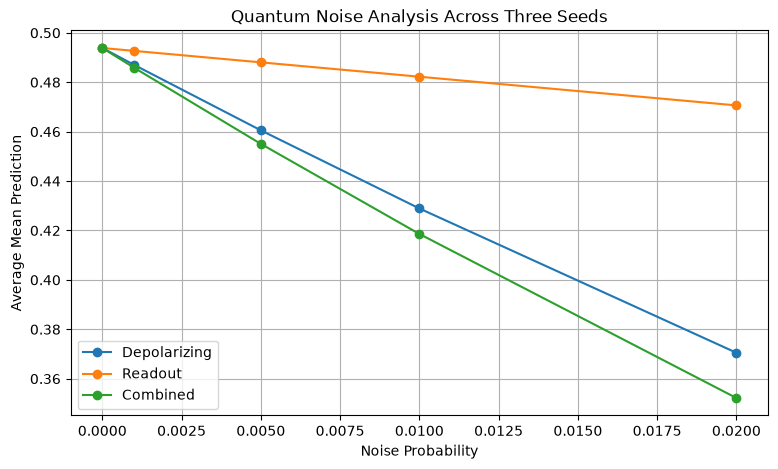

Average table and graph saved successfully!


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Average results across three seeds
summary_df = (
    all_seeds_df
    .groupby(["Noise Type", "Noise Level"])
    ["Mean Prediction"]
    .agg(["mean", "std"])
    .reset_index()
)

summary_df = summary_df.rename(columns={
    "mean": "Average Prediction",
    "std": "Variation Across Seeds"
})
print("AVERAGE NOISE ANALYSIS ACROSS THREE SEEDS")
print(summary_df)

# Save summary
summary_df.to_csv(
    "results/tables/noise_analysis_seed_average.csv",
    index=False
)

# Plot average results
plt.figure(figsize=(9, 5))

for noise_type in ["Depolarizing", "Readout", "Combined"]:

    subset = summary_df[
        summary_df["Noise Type"] == noise_type
    ]

    plt.plot(
        subset["Noise Level"],
        subset["Average Prediction"],
        marker="o",
        label=noise_type
    )

plt.xlabel("Noise Probability")
plt.ylabel("Average Mean Prediction")
plt.title("Quantum Noise Analysis Across Three Seeds")
plt.legend()
plt.grid(True)

os.makedirs("results/figures", exist_ok=True)

plt.savefig(
    "results/figures/noise_analysis_all_seeds.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Average table and graph saved successfully!")

In [26]:
import os

print(
    "Graph exists:",
    os.path.exists("results/figures/noise_analysis_all_seeds.png")
)

print(
    "Average CSV exists:",
    os.path.exists("results/tables/noise_analysis_seed_average.csv")
)

Graph exists: True
Average CSV exists: True


In [27]:
import numpy as np
import torch

from src.quantum.quantum_model import load_model

# Load ideal model with 1024 measurement shots
model, mu, sd = load_model(
    "models/qnn_ideal_seed0.pt",
    p_dep=0.0,
    p_ro=0.0,
    shots=1024
)

# Use only 5 test samples for this initial test
X_test = np.load("data/processed/X_test.npy")
X_small = X_test[:5, :4]

# Apply training normalization
X_scaled = (X_small - mu) / sd

X_tensor = torch.tensor(
    X_scaled,
    dtype=torch.float64
)

# First prediction
with torch.no_grad():
    pred1 = model(X_tensor).cpu().numpy()

# Second prediction
with torch.no_grad():
    pred2 = model(X_tensor).cpu().numpy()

print("First prediction:", pred1)
print("Second prediction:", pred2)

print("\nPrediction differences:")
print(np.abs(pred1 - pred2))

print("\nFinite-shot test completed!")

First prediction: [0.59406109 0.56697074 0.30970947 0.56990213 0.54767226]
Second prediction: [0.56815793 0.55977573 0.35766634 0.63030152 0.54213135]

Prediction differences:
[0.02590316 0.00719501 0.04795687 0.06039939 0.00554091]

Finite-shot test completed!


C:\Users\rsaho\.conda\envs\member5\Lib\site-packages\pennylane\devices\device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


In [28]:
import numpy as np
import torch

from src.quantum.quantum_model import load_model

# Load the ideal model
model, mu, sd = load_model(
    "models/qnn_ideal_seed0.pt",
    p_dep=0.0,
    p_ro=0.0,
    shots=1024
)

# Select five test samples
X_test = np.load("data/processed/X_test.npy")
X_small = X_test[:5, :4]

# Normalize
X_scaled = (X_small - mu) / sd

X_tensor = torch.tensor(
    X_scaled,
    dtype=torch.float64
)

# Perform 20 repeated predictions
repeated_predictions = []

for repeat in range(20):

    with torch.no_grad():
        predictions = model(X_tensor).cpu().numpy()

    repeated_predictions.append(predictions)

    print(f"Completed repetition {repeat + 1}/20")

# Convert to NumPy array
repeated_predictions = np.array(repeated_predictions)

# Calculate stability
mean_predictions = np.mean(repeated_predictions, axis=0)
std_predictions = np.std(repeated_predictions, axis=0)

print("\nROBUSTNESS RESULTS")

for i in range(5):
    print(
        f"Sample {i+1}: "
        f"Mean = {mean_predictions[i]:.6f}, "
        f"Std = {std_predictions[i]:.6f}"
    )

print("\nRepeated prediction shape:", repeated_predictions.shape)
print("20-repetition test completed!")

C:\Users\rsaho\.conda\envs\member5\Lib\site-packages\pennylane\devices\device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


Completed repetition 1/20
Completed repetition 2/20
Completed repetition 3/20
Completed repetition 4/20
Completed repetition 5/20
Completed repetition 6/20
Completed repetition 7/20
Completed repetition 8/20
Completed repetition 9/20
Completed repetition 10/20
Completed repetition 11/20
Completed repetition 12/20
Completed repetition 13/20
Completed repetition 14/20
Completed repetition 15/20
Completed repetition 16/20
Completed repetition 17/20
Completed repetition 18/20
Completed repetition 19/20
Completed repetition 20/20

ROBUSTNESS RESULTS
Sample 1: Mean = 0.592380, Std = 0.026269
Sample 2: Mean = 0.560185, Std = 0.029375
Sample 3: Mean = 0.335910, Std = 0.031532
Sample 4: Mean = 0.569720, Std = 0.033479
Sample 5: Mean = 0.519528, Std = 0.032795

Repeated prediction shape: (20, 5)
20-repetition test completed!


In [29]:
import inspect

from src.quantum.quantum_model import load_model, make_qlayer

print("load_model source:")
print(inspect.getsource(load_model))

print("\nmake_qlayer source:")
print(inspect.getsource(make_qlayer))

load_model source:
def load_model(path, p_dep=0.0, p_ro=0.0, shots=None):
    ck = torch.load(path, weights_only=False)
    m = HybridQNN(ck['n_qubits'], ck['n_layers'], p_dep, p_ro, shots)
    m.load_state_dict(ck['state'])
    m.eval()
    return m, ck['mu'], ck['sd']


make_qlayer source:
def make_qlayer(n_qubits=4, n_layers=3, p_dep=0.0, p_ro=0.0, shots=None):
    noisy = (p_dep > 0) or (p_ro > 0)
    dev = qml.device('default.mixed' if noisy else 'default.qubit', wires=n_qubits, shots=shots)
    diff = 'parameter-shift' if shots else 'backprop'

    @qml.qnode(dev, interface='torch', diff_method=diff)
    def circuit(inputs, weights):
        qml.AngleEmbedding(inputs * math.pi, wires=range(n_qubits), rotation='Y')
        if p_dep > 0:
            for w in range(n_qubits):
                qml.DepolarizingChannel(p_dep, wires=w)
        for l in range(n_layers):
            qml.StronglyEntanglingLayers(weights[l:l + 1], wires=range(n_qubits))
            if p_dep > 0:
            

In [30]:
import os

checkpoint_files = [
    f"models/qnn_{model_type}_seed{seed}.pt"
    for model_type in ["ideal", "noise_aware"]
    for seed in [0, 1, 2]
]

print("CHECKPOINT VERIFICATION")

for file in checkpoint_files:
    print(file, ":", os.path.exists(file))

CHECKPOINT VERIFICATION
models/qnn_ideal_seed0.pt : True
models/qnn_ideal_seed1.pt : True
models/qnn_ideal_seed2.pt : True
models/qnn_noise_aware_seed0.pt : True
models/qnn_noise_aware_seed1.pt : True
models/qnn_noise_aware_seed2.pt : True


In [31]:
import os
import numpy as np
import pandas as pd
import torch

from src.quantum.quantum_model import load_model

# Experiment configuration
noise_levels = [0.0, 0.001, 0.005, 0.01, 0.02]
seeds = [0, 1, 2]
model_types = ["ideal", "noise_aware"]
noise_types = {
    "Depolarizing": (1, 0),
    "Readout": (0, 1),
    "Combined": (1, 1)
}

shots = 1024
repeats = 20

# Load actual test dataset
X_test = np.load("data/processed/X_test.npy")
X_test = X_test[:, :4]

# Create output folders
os.makedirs("results/tables", exist_ok=True)
os.makedirs("results/predictions", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)

results = []

total = (
    len(model_types)
    * len(seeds)
    * len(noise_types)
    * len(noise_levels)
)

completed = 0

# Run experiment
for model_type in model_types:

    for seed in seeds:

        checkpoint = f"models/qnn_{model_type}_seed{seed}.pt"

        for noise_name, (dep, ro) in noise_types.items():

            for p in noise_levels:

                print(
                    f"\nModel: {model_type} | Seed: {seed} | "
                    f"Noise: {noise_name} | Level: {p}"
                )

                model, mu, sd = load_model(
                    checkpoint,
                    p_dep=dep * p,
                    p_ro=ro * p,
                    shots=shots
                )

                X_scaled = (X_test - mu) / sd

                X_tensor = torch.tensor(
                    X_scaled,
                    dtype=torch.float64
                )

                repeated_predictions = []

                for repeat in range(repeats):

                    with torch.no_grad():
                        pred = model(X_tensor).cpu().numpy()

                    repeated_predictions.append(pred)

                repeated_predictions = np.asarray(
                    repeated_predictions
                )

                results.append({
                    "Model": model_type,
                    "Seed": seed,
                    "Noise Type": noise_name,
                    "Noise Level": p,
                    "Shots": shots,
                    "Repeats": repeats,
                    "Mean Prediction": float(
                        repeated_predictions.mean()
                    ),
                    "Mean Prediction Std": float(
                        repeated_predictions.std()
                    ),
                    "Average Sample Std": float(
                        repeated_predictions.std(axis=0).mean()
                    )
                })

                # Save individual predictions
                prediction_filename = (
                    f"{model_type}_seed{seed}_"
                    f"{noise_name.lower()}_p{p}.npy"
                )

                np.save(
                    f"results/predictions/{prediction_filename}",
                    repeated_predictions
                )

                completed += 1

                # Save progress after every configuration
                results_df = pd.DataFrame(results)

                results_df.to_csv(
                    "results/tables/full_robustness_progress.csv",
                    index=False
                )

                print(
                    f"Completed {completed}/{total} configurations"
                )

print("\nFULL FINITE-SHOT ROBUSTNESS EXPERIMENT COMPLETED!")


Model: ideal | Seed: 0 | Noise: Depolarizing | Level: 0.0


C:\Users\rsaho\.conda\envs\member5\Lib\site-packages\pennylane\devices\device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


Completed 1/90 configurations

Model: ideal | Seed: 0 | Noise: Depolarizing | Level: 0.001


C:\Users\rsaho\.conda\envs\member5\Lib\site-packages\pennylane\devices\device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


Completed 2/90 configurations

Model: ideal | Seed: 0 | Noise: Depolarizing | Level: 0.005


C:\Users\rsaho\.conda\envs\member5\Lib\site-packages\pennylane\devices\device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


... (171 outputs left out)

C:\Users\rsaho\.conda\envs\member5\Lib\site-packages\pennylane\devices\device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


Completed 89/90 configurations

Model: noise_aware | Seed: 2 | Noise: Combined | Level: 0.02


C:\Users\rsaho\.conda\envs\member5\Lib\site-packages\pennylane\devices\device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


Completed 90/90 configurations

FULL FINITE-SHOT ROBUSTNESS EXPERIMENT COMPLETED!


In [32]:
import pandas as pd

results_df = pd.read_csv(
    "results/tables/full_robustness_progress.csv"
)

print("Total configurations:", len(results_df))

display(results_df.head(10))

print("\nAvailable columns:")
print(results_df.columns.tolist())

Total configurations: 90


,Model,Seed,Noise Type,Noise Level,Shots,Repeats,Mean Prediction,Mean Prediction Std,Average Sample Std
0,ideal,0,Depolarizing,0.000,1024,20,0.561002,0.104233,0.033391
1,ideal,0,Depolarizing,0.001,1024,20,0.552289,0.102067,0.032780
2,ideal,0,Depolarizing,0.005,1024,20,0.524037,0.098257,0.033257
3,ideal,0,Depolarizing,0.010,1024,20,0.489965,0.092340,0.033505
4,ideal,0,Depolarizing,0.020,1024,20,0.427570,0.083096,0.033321
5,ideal,0,Readout,0.000,1024,20,0.560258,0.104039,0.032483
6,ideal,0,Readout,0.001,1024,20,0.559251,0.102097,0.033464
7,ideal,0,Readout,0.005,1024,20,0.552480,0.102141,0.033122
8,ideal,0,Readout,0.010,1024,20,0.548042,0.102126,0.031726
9,ideal,0,Readout,0.020,1024,20,0.534142,0.097803,0.032443



Available columns:
['Model', 'Seed', 'Noise Type', 'Noise Level', 'Shots', 'Repeats', 'Mean Prediction', 'Mean Prediction Std', 'Average Sample Std']


In [33]:
import pandas as pd

# Load completed experiment
df = pd.read_csv(
    "results/tables/full_robustness_progress.csv"
)

# Average results across three seeds
summary = (
    df.groupby(["Model", "Noise Type", "Noise Level"])
    [["Mean Prediction", "Average Sample Std"]]
    .mean()
    .reset_index()
)

print("AVERAGE RESULTS ACROSS THREE SEEDS")
display(summary)

# Save summary
summary.to_csv(
    "results/tables/robustness_summary.csv",
    index=False
)

print("Saved: results/tables/robustness_summary.csv")

AVERAGE RESULTS ACROSS THREE SEEDS


,Model,Noise Type,Noise Level,Mean Prediction,Average Sample Std
0,ideal,Combined,0.000,0.494227,0.041264
1,ideal,Combined,0.001,0.484975,0.041195
2,ideal,Combined,0.005,0.454901,0.040785
3,ideal,Combined,0.010,0.417967,0.042051
4,ideal,Combined,0.020,0.352022,0.042421
5,ideal,Depolarizing,0.000,0.494615,0.042140
6,ideal,Depolarizing,0.001,0.486386,0.041152
7,ideal,Depolarizing,0.005,0.460521,0.041555
8,ideal,Depolarizing,0.010,0.429380,0.041861
9,ideal,Depolarizing,0.020,0.371147,0.041885


Saved: results/tables/robustness_summary.csv


In [34]:
import os
import numpy as np
import pandas as pd

noise_levels = [0.0, 0.001, 0.005, 0.01, 0.02]
seeds = [0, 1, 2]
model_types = ["ideal", "noise_aware"]

noise_types = ["Depolarizing", "Readout", "Combined"]

deviation_results = []

for model_type in model_types:
    for seed in seeds:

        # Load the zero-noise baseline
        baseline_path = (
            f"results/predictions/"
            f"{model_type}_seed{seed}_depolarizing_p0.0.npy"
        )

        baseline = np.load(baseline_path).mean(axis=0)

        for noise_type in noise_types:
            for p in noise_levels:

                filename = (
                    f"results/predictions/"
                    f"{model_type}_seed{seed}_"
                    f"{noise_type.lower()}_p{p}.npy"
                )

                predictions = np.load(filename)

                # Average repeated predictions for each sample
                sample_mean = predictions.mean(axis=0)

                # Compare against the same model's baseline
                difference = sample_mean - baseline

                deviation_results.append({
                    "Model": model_type,
                    "Seed": seed,
                    "Noise Type": noise_type,
                    "Noise Level": p,
                    "MAE Shift": np.mean(np.abs(difference)),
                    "RMSE Shift": np.sqrt(np.mean(difference**2)),
                    "Average Sample Std": predictions.std(axis=0).mean()
                })

deviation_df = pd.DataFrame(deviation_results)

# Average across the three seeds
deviation_summary = (
    deviation_df.groupby(
        ["Model", "Noise Type", "Noise Level"]
    )
    [["MAE Shift", "RMSE Shift", "Average Sample Std"]]
    .mean()
    .reset_index()
)

os.makedirs("results/tables", exist_ok=True)

deviation_summary.to_csv(
    "results/tables/prediction_deviation_summary.csv",
    index=False
)

print("PREDICTION DEVIATION ANALYSIS COMPLETED!")
display(deviation_summary)

print("\nSaved: results/tables/prediction_deviation_summary.csv")

PREDICTION DEVIATION ANALYSIS COMPLETED!


,Model,Noise Type,Noise Level,MAE Shift,RMSE Shift,Average Sample Std
0,ideal,Combined,0.000,0.011226,0.013808,0.041264
1,ideal,Combined,0.001,0.014033,0.017076,0.041195
2,ideal,Combined,0.005,0.040869,0.043775,0.040785
3,ideal,Combined,0.010,0.077010,0.080507,0.042051
4,ideal,Combined,0.020,0.142611,0.147976,0.042421
5,ideal,Depolarizing,0.000,0.000000,0.000000,0.042140
6,ideal,Depolarizing,0.001,0.013676,0.016745,0.041152
7,ideal,Depolarizing,0.005,0.035330,0.038157,0.041555
8,ideal,Depolarizing,0.010,0.066025,0.069736,0.041861
9,ideal,Depolarizing,0.020,0.123503,0.128562,0.041885



Saved: results/tables/prediction_deviation_summary.csv


In [35]:
import numpy as np
import pandas as pd
import os

model_types = ["ideal", "noise_aware"]
seeds = [0, 1, 2]

noise_types = ["Depolarizing", "Readout", "Combined"]

noise_levels = [0.0, 0.001, 0.005, 0.01, 0.02]

corrected_results = []

for model_type in model_types:
    for seed in seeds:

        for noise_type in noise_types:

            # Use the matching noise type's zero-level baseline
            baseline_file = (
                f"results/predictions/"
                f"{model_type}_seed{seed}_"
                f"{noise_type.lower()}_p0.0.npy"
            )

            baseline = np.load(baseline_file).mean(axis=0)

            for p in noise_levels:

                filename = (
                    f"results/predictions/"
                    f"{model_type}_seed{seed}_"
                    f"{noise_type.lower()}_p{p}.npy"
                )

                predictions = np.load(filename)

                sample_mean = predictions.mean(axis=0)

                difference = sample_mean - baseline

                corrected_results.append({
                    "Model": model_type,
                    "Seed": seed,
                    "Noise Type": noise_type,
                    "Noise Level": p,
                    "MAE Shift": np.mean(np.abs(difference)),
                    "RMSE Shift": np.sqrt(np.mean(difference**2)),
                    "Average Sample Std": predictions.std(axis=0).mean()
                })

corrected_df = pd.DataFrame(corrected_results)

corrected_summary = (
    corrected_df.groupby(
        ["Model", "Noise Type", "Noise Level"]
    )[
        ["MAE Shift", "RMSE Shift", "Average Sample Std"]
    ]
    .mean()
    .reset_index()
)

corrected_summary.to_csv(
    "results/tables/corrected_prediction_deviation.csv",
    index=False
)

print("CORRECTED ROBUSTNESS ANALYSIS COMPLETED!")
display(corrected_summary)

CORRECTED ROBUSTNESS ANALYSIS COMPLETED!


,Model,Noise Type,Noise Level,MAE Shift,RMSE Shift,Average Sample Std
0,ideal,Combined,0.000,0.000000,0.000000,0.041264
1,ideal,Combined,0.001,0.014531,0.017483,0.041195
2,ideal,Combined,0.005,0.039998,0.043026,0.040785
3,ideal,Combined,0.010,0.076525,0.079875,0.042051
4,ideal,Combined,0.020,0.142258,0.147456,0.042421
5,ideal,Depolarizing,0.000,0.000000,0.000000,0.042140
6,ideal,Depolarizing,0.001,0.013676,0.016745,0.041152
7,ideal,Depolarizing,0.005,0.035330,0.038157,0.041555
8,ideal,Depolarizing,0.010,0.066025,0.069736,0.041861
9,ideal,Depolarizing,0.020,0.123503,0.128562,0.041885


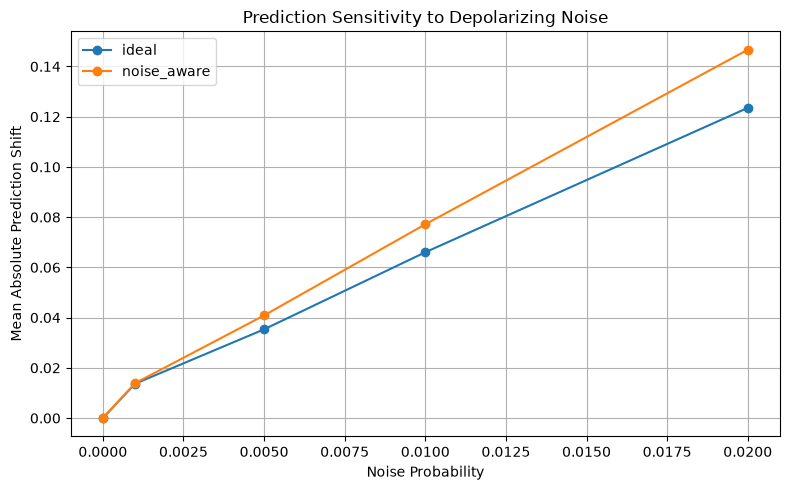

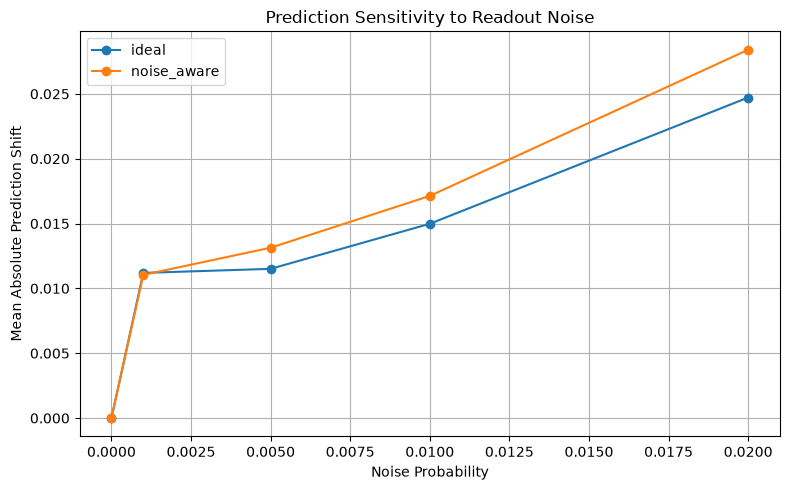

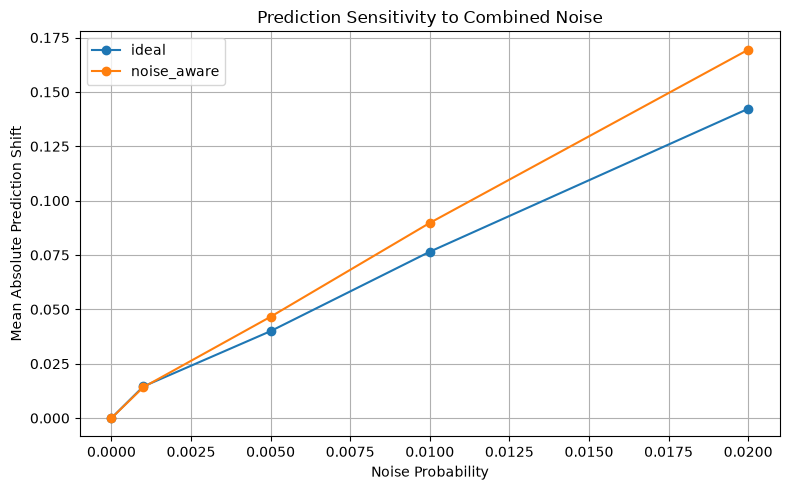

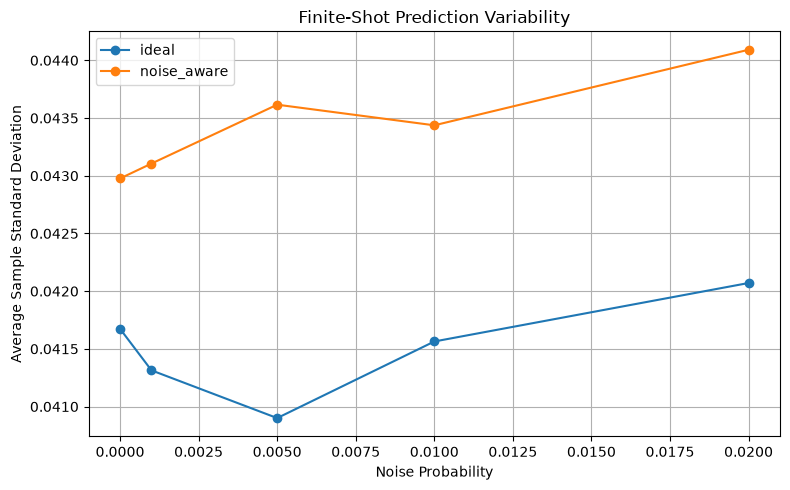

All robustness graphs generated successfully!


In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import os

df = pd.read_csv(
    "results/tables/corrected_prediction_deviation.csv"
)

os.makedirs("results/figures", exist_ok=True)

# Graph 1: Prediction deviation under different noise types

for noise_type in ["Depolarizing", "Readout", "Combined"]:

    plt.figure(figsize=(8, 5))

    subset = df[df["Noise Type"] == noise_type]

    for model in ["ideal", "noise_aware"]:

        model_data = subset[subset["Model"] == model]

        plt.plot(
            model_data["Noise Level"],
            model_data["MAE Shift"],
            marker="o",
            label=model
        )

    plt.xlabel("Noise Probability")
    plt.ylabel("Mean Absolute Prediction Shift")
    plt.title(f"Prediction Sensitivity to {noise_type} Noise")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    filename = (
        f"results/figures/"
        f"prediction_shift_{noise_type.lower()}.png"
    )

    plt.savefig(filename, dpi=300)
    plt.show()

# Graph 2: Finite-shot prediction variability

plt.figure(figsize=(8, 5))

for model in ["ideal", "noise_aware"]:

    model_data = (
        df[df["Model"] == model]
        .groupby("Noise Level")["Average Sample Std"]
        .mean()
    )

    plt.plot(
        model_data.index,
        model_data.values,
        marker="o",
        label=model
    )

plt.xlabel("Noise Probability")
plt.ylabel("Average Sample Standard Deviation")
plt.title("Finite-Shot Prediction Variability")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "results/figures/finite_shot_variability.png",
    dpi=300
)

plt.show()

print("All robustness graphs generated successfully!")